# 04 · Impagos y cascadas

Umbral $x_i^{(c)} = c\,\mathrm{out}_i\,\varepsilon_i$; al cruzarlo, la columna de $W$ se anula y los receptores pierden ingreso.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

FIG = Path("..") / "figures"
FIG.mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 150, "axes.grid": True,
                     "grid.alpha": 0.3, "axes.spines.top": False, "axes.spines.right": False})
TOPO_LABEL = {"erdos_renyi": "Erdős–Rényi", "barabasi_albert": "Barabási–Albert",
              "core_periphery": "Núcleo-periferia"}

## Ventana de contagio (Erdős–Rényi)
Fracción en impago tras chocar la entidad que más paga, contra grado medio (R = 0.8, colchón c = 0.3). Comparación con DebtRank y Watts (φ = 0.18). Con pocas conexiones la red está fragmentada; con muchas, cada pagador pesa poco en el ingreso de sus receptores: el contagio vive en medio.

,dinamica,debtrank,watts
k,,,
1.0,0.125,0.125,0.160
2.5,0.800,0.143,0.891
4.0,0.796,0.117,0.977
5.5,0.905,0.105,0.899
7.0,0.807,0.098,0.802
8.5,0.618,0.088,0.407
10.0,0.619,0.082,0.505
11.5,0.429,0.078,0.010
13.0,0.438,0.079,0.012


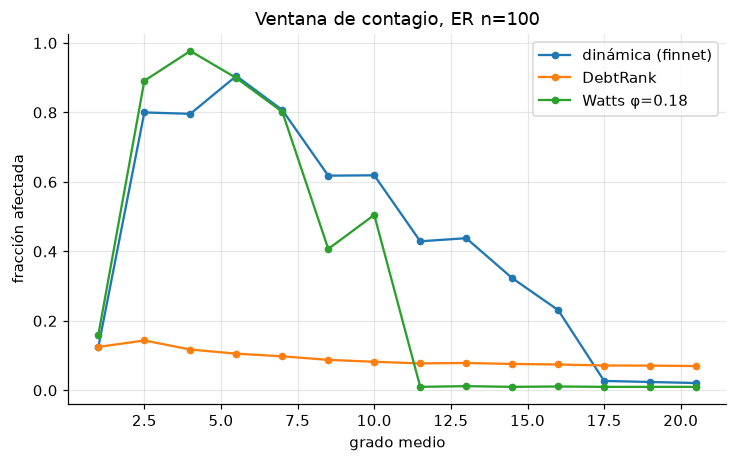

In [2]:
from pulso.cascades import debtrank, watts
from pulso.integrate import Shock, simulate
from pulso.model import Params, make_thresholds
from pulso.networks import NetworkConfig, generate
from pulso.spectral import perron_root

ks = np.arange(1.0, 21.0, 1.5)
rows = []
for k in ks:
    for s in range(10):
        W = generate(NetworkConfig("erdos_renyi", 100, float(k), 0.6, 0.1, 0.8, 0.1, seed=s))
        rng = np.random.default_rng(s)
        p = Params(alpha=1.0, beta=0.8 / max(perron_root(W), 1e-9), loss=1.0,
                   thresholds=make_thresholds(W, 0.3, 0.3, rng))
        tgt = int(np.argmax(W.sum(0)))
        tr = simulate(W, p, t_end=15, dt=0.02, shock=Shock("liquidity", (tgt,), size=3.0), save_every=10**9)
        h0 = np.zeros(100); h0[tgt] = 1
        rows.append({"k": k, "dinamica": tr.defaulted.mean(),
                     "debtrank": debtrank(W, h0)["R"],
                     "watts": watts(W, 0.18, [tgt]).mean()})
win = pd.DataFrame(rows).groupby("k").mean()
fig, ax = plt.subplots(figsize=(6.8, 4.3))
for col, lab in [("dinamica", "dinámica (pulso)"), ("debtrank", "DebtRank"), ("watts", "Watts φ=0.18")]:
    ax.plot(win.index, win[col], "o-", ms=4, label=lab)
ax.set(xlabel="grado medio", ylabel="fracción afectada", title="Ventana de contagio, ER n=100"); ax.legend()
fig.tight_layout(); fig.savefig(FIG / "fase4_ventana_contagio.png")
win.round(3)

## Caída operativa contra retiro de liquidez
Misma entidad (la que más paga) en núcleo-periferia; tamaño del retiro vs duración de la caída.

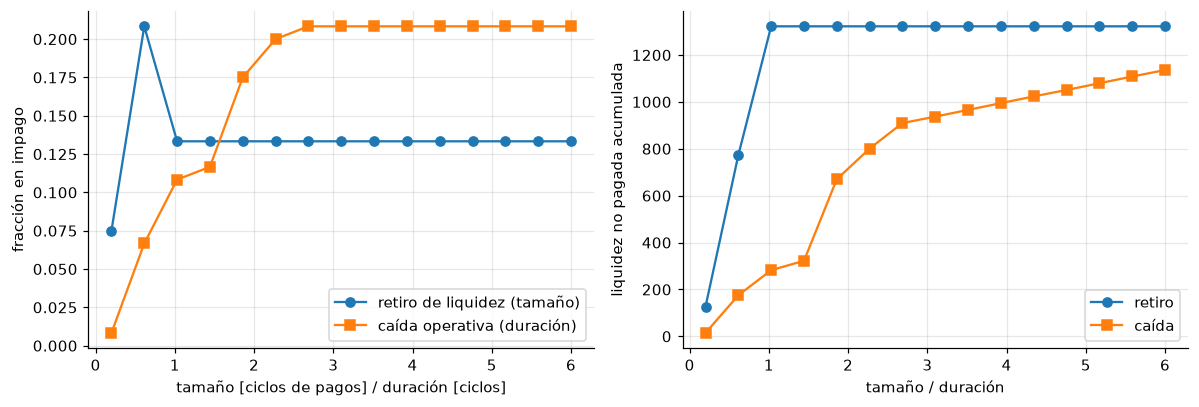

In [3]:
W = generate(NetworkConfig("core_periphery", 120, 6.0, 0.8, 0.1, 0.8, 0.1, seed=3))
rng = np.random.default_rng(0)
p = Params(alpha=1.0, beta=0.7 / perron_root(W), loss=1.0, thresholds=make_thresholds(W, 0.5, 0.3, rng))
tgt = int(np.argmax(W.sum(0)))
liq = [simulate(W, p, 15, 0.02, shock=Shock("liquidity", (tgt,), size=s), save_every=10**9) for s in np.linspace(0.2, 6, 15)]
op = [simulate(W, p, 15, 0.02, shock=Shock("operational", (tgt,), duration=d), save_every=10**9) for d in np.linspace(0.2, 6, 15)]
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
x = np.linspace(0.2, 6, 15)
ax[0].plot(x, [t.defaulted.mean() for t in liq], "o-", label="retiro de liquidez (tamaño)")
ax[0].plot(x, [t.defaulted.mean() for t in op], "s-", label="caída operativa (duración)")
ax[0].set(xlabel="tamaño [ciclos de pagos] / duración [ciclos]", ylabel="fracción en impago"); ax[0].legend()
ax[1].plot(x, [t.unpaid[-1] for t in liq], "o-", label="retiro"); ax[1].plot(x, [t.unpaid[-1] for t in op], "s-", label="caída")
ax[1].set(xlabel="tamaño / duración", ylabel="liquidez no pagada acumulada"); ax[1].legend()
fig.tight_layout(); fig.savefig(FIG / "fase4_operativa_vs_liquidez.png")